# Bank Customer Churn: Building, Owning and Monitoring a Model

**Business context.** A retail bank loses about 1 in 5 customers. Keeping a customer is far cheaper than winning a new one, so the bank wants to
**predict who is likely to leave** and offer them a reason to stay (a better rate, a fee waiver, a call from an adviser).

**What this project is really about: model ownership.** Building the model is about a third of the work. Owning it means:
1. making defensible choices about which data the model may use, and documenting them;
2. choosing the model in a fair, repeatable way;
3. checking that its probabilities can be trusted and that it treats customer groups fairly;
4. **monitoring it after deployment**, with clear thresholds and actions, because the world changes after the model is built.

Part 4 is simulated here: a year of production with drift and a market shock, feeding a **Power BI monitoring dashboard** (`powerbi/POWERBI_BUILD_GUIDE.md`).
The model is documented in `MODEL_CARD.md`.

**Dataset.** *Churn Modelling* ([Kaggle](https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling)): 10,000 customers of a European retail bank (France, Germany, Spain),
with whether each customer left (`Exited`). Amounts are treated as euros.

**Outline**
1. Setup and data loading
2. Data dictionary and data-quality checks
3. Exploratory analysis
4. Which columns may the model use? (fair lending)
5. Features and the shared pipeline
6. Comparing four models
7. Evaluating the selected model
8. What drives the predictions
9. Retention economics: whom to contact
10. Fairness at development
11. Monitoring design
12. A simulated production year
13. Reading the year: what monitoring caught, and what to do
14. Exporting tables for Power BI
15. Limitations

> **How to read this notebook:** each section starts with *what* the step does and *why*.
> Code cells have inline comments (lines starting with `#`) explaining each line.

## 1. Setup and data loading

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RANDOM_STATE = 42
TARGET = "Exited"
NAVY, AMBER, RED, GREEN, GREY = "#2C3E50", "#D4A20B", "#B9603A", "#2E7D5B", "#95A5A6"
FIG_DIR, EXPORT_DIR = "../reports/figures", "../powerbi/data"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(EXPORT_DIR, exist_ok=True)

In [2]:
DATA_DIR = "../data"
CSV_PATH = os.path.join(DATA_DIR, "Churn_Modelling.csv")
URL = "https://raw.githubusercontent.com/sagnikghoshcr7/Bank-Customer-Churn-Prediction/master/Churn_Modelling.csv"
if not os.path.exists(CSV_PATH):           # download only if the file isn't already in data/
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(URL, CSV_PATH)

df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.000,1,1,1,"101,348.880",1
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.860",1,0,1,"112,542.580",0
2,3,15619304,Onio,502,France,Female,42,8,"159,660.800",3,1,0,"113,931.570",1
3,4,15701354,Boni,699,France,Female,39,1,0.000,2,0,0,"93,826.630",0
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.820",1,1,1,"79,084.100",0


## 2. Data dictionary and data-quality checks

| Column | Meaning | Use |
|---|---|---|
| `RowNumber`, `CustomerId` | Row number, customer identifier | Identifier only |
| `Surname` | Customer's surname | **Never used** (personal data with no legitimate predictive role) |
| `CreditScore` | Credit score | Feature |
| `Geography` | Country: France, Germany or Spain | Feature |
| `Gender`, `Age` | Demographics | **Not used** by the model; monitored for fairness (Section 4) |
| `Tenure` | Years as a customer | Feature |
| `Balance` | Account balance | Feature |
| `NumOfProducts` | Number of bank products held (1–4) | Feature |
| `HasCrCard`, `IsActiveMember` | Holds a credit card; is an active member (0/1) | Features |
| `EstimatedSalary` | Estimated salary | Feature |
| `Exited` | **Target**: 1 = left the bank | |

In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate customer IDs:", df["CustomerId"].duplicated().sum())
print(f"Churn rate: {df[TARGET].mean():.2%}  ({df[TARGET].sum():,} of {len(df):,})")
print(f"Customers with a zero balance: {(df['Balance'] == 0).mean():.1%}")
print("Products held:", df["NumOfProducts"].value_counts().sort_index().to_dict())

Missing values: 0
Duplicate customer IDs: 0
Churn rate: 20.37%  (2,037 of 10,000)
Customers with a zero balance: 36.2%
Products held: {1: 5084, 2: 4590, 3: 266, 4: 60}


The data is clean: no missing values or duplicates. Two things to note:
- **36% of customers have a zero balance.** That's a real state (they may only hold a card or another product), not missing data.
- **Very few customers hold 3 or 4 products** (326 in total), which matters for the next section.

## 3. Exploratory analysis

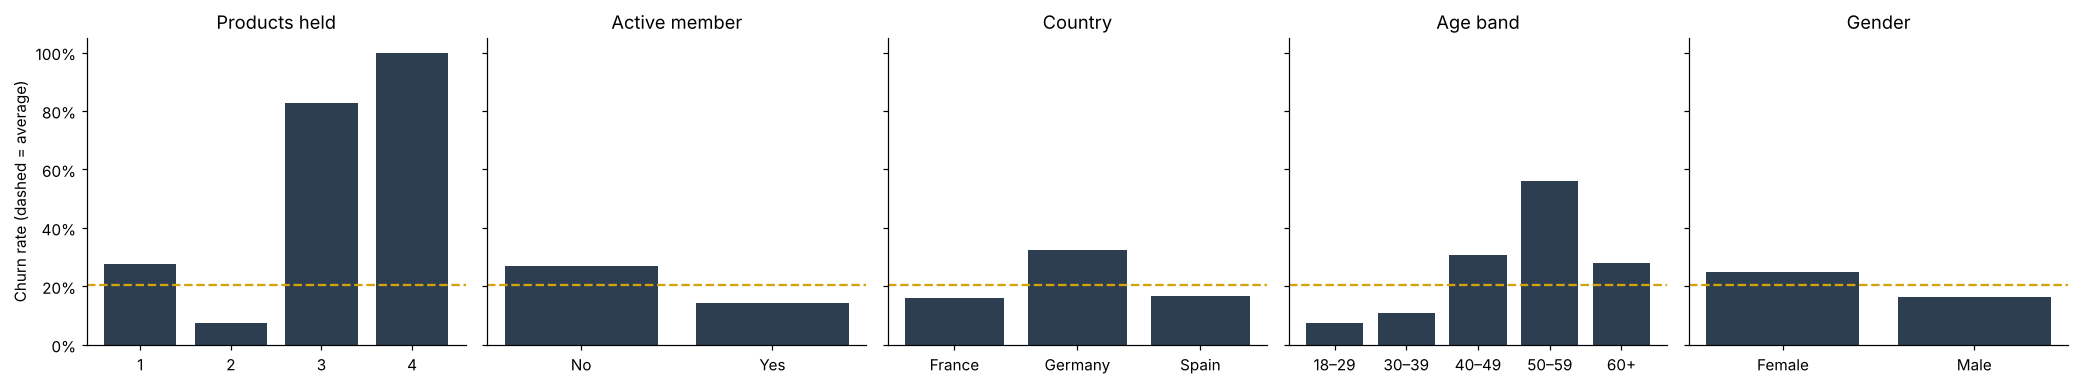

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(19, 3.6), sharey=True)
groups = [("Products held", df["NumOfProducts"].astype(str)), ("Active member", df["IsActiveMember"].map({0: "No", 1: "Yes"})),
          ("Country", df["Geography"]), ("Age band", pd.cut(df["Age"], [0, 29, 39, 49, 59, 120], labels=["18–29", "30–39", "40–49", "50–59", "60+"])),
          ("Gender", df["Gender"])]
for ax, (title, g) in zip(axes, groups):
    rate = df.groupby(g, observed=True)[TARGET].mean()
    ax.bar(rate.index.astype(str), rate.values, color=NAVY)
    ax.axhline(df[TARGET].mean(), color=AMBER, ls="--", lw=1.5)
    ax.set_title(title); ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("Churn rate (dashed = average)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/01_churn_rates.png", dpi=120, bbox_inches="tight"); plt.show()

**Takeaways**
- **Products held is not a straight line:** churn is 28% with 1 product, only 8% with 2, and 83–100% with 3 or 4. So it will be treated as a **category**, not a number:
  a linear model would otherwise assume "more products = steadily more (or less) churn".
- **Inactive customers churn about twice as often** as active ones.
- **Germany's churn rate is double** France's and Spain's.
- **Age has the strongest pattern** (rising sharply to the 50s), and **women churn more than men**. Both are protected characteristics: see the next section.

## 4. Which columns may the model use? (fair lending)

The **Canadian Human Rights Act** prohibits discrimination in services on grounds that include **sex and age**. Even for a marketing model
(deciding who receives a retention offer), using these attributes means customers are treated differently because of who they are.

So the default is to **leave them out**, and to measure what that costs, so the trade-off is an informed decision rather than an accident:

In [5]:
BASE_NUM = ["CreditScore", "Tenure", "Balance", "HasCrCard", "IsActiveMember", "EstimatedSalary"]
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def forest(numeric, categorical):
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), categorical), ("num", "passthrough", numeric)])
    return Pipeline([("prep", prep), ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features=0.5,
                                                                      n_jobs=-1, random_state=RANDOM_STATE))])

variants = {"All columns (incl. gender and age)": (BASE_NUM + ["Age"], ["Geography", "NumOfProducts", "Gender"]),
            "Without gender": (BASE_NUM + ["Age"], ["Geography", "NumOfProducts"]),
            "Without gender and age (selected)": (BASE_NUM, ["Geography", "NumOfProducts"])}
for label, (num, cat) in variants.items():
    auc = cross_val_score(forest(num, cat), train_df[num + cat], train_df[TARGET], cv=cv, scoring="roc_auc").mean()
    print(f"{label:38s} 5-fold CV AUC = {auc:.3f}")

All columns (incl. gender and age)     5-fold CV AUC = 0.861


Without gender                         5-fold CV AUC = 0.858


Without gender and age (selected)      5-fold CV AUC = 0.806


**The decision and its cost**
- **Gender adds almost nothing** once the other columns are in (about 0.003 of AUC), so dropping it costs essentially nothing.
- **Age is a strong predictor**: leaving it out costs about **0.05 of AUC**. That is a real loss in campaign efficiency.
- **Selected: leave out both.** This keeps the model consistent with how the bank treats protected grounds elsewhere (see the credit default project).
  The cost is documented, and Section 10 shows a side-effect worth knowing: the model then under-predicts churn for older customers.
- **This is a compliance decision, not a data-science one.** If compliance confirmed that using age for a *benefit-only* action (offering something extra, never withholding) is acceptable,
  the "without gender" variant is ready, and its performance is known. The owner's job is to make the trade-off visible.

`Geography` (country of the customer's branch) is kept: it reflects where the bank operates, not the customer's national origin. A validator should still check it isn't acting as a proxy.

## 5. Features and the shared pipeline

| Type | Columns | Preparation |
|---|---|---|
| Categorical | `Geography`, `NumOfProducts` | One-hot encoding |
| Numeric | `CreditScore`, `Tenure`, `Balance`, `HasCrCard`, `IsActiveMember`, `EstimatedSalary` | Standardised for logistic regression; left as they are for trees |

Every candidate model sits in the **same scikit-learn `Pipeline`** (preprocessing + model), so all four see identical data,
cross-validation re-fits the preprocessing inside each fold (no leakage), and the deployed object is a single, versionable unit.

In [6]:
CATEGORICAL = ["Geography", "NumOfProducts"]
NUMERIC = BASE_NUM
FEATURES = CATEGORICAL + NUMERIC
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

def prep(scale):
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
                              ("num", StandardScaler() if scale else "passthrough", NUMERIC)])

candidates = {
    "Logistic regression": Pipeline([("prep", prep(True)), ("model", LogisticRegression(max_iter=2000))]),
    "Decision tree": Pipeline([("prep", prep(False)), ("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=RANDOM_STATE))]),
    "Random forest": Pipeline([("prep", prep(False)), ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features=0.5,
                                                                                         n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient boosting": Pipeline([("prep", prep(False)), ("model", HistGradientBoostingClassifier(learning_rate=0.1, max_depth=3,
                                                                                                  min_samples_leaf=20, random_state=RANDOM_STATE))]),
}
print(f"Train: {len(train_df):,} customers, churn {y_train.mean():.1%} | Test: {len(test_df):,} customers, churn {y_test.mean():.1%}")

Train: 8,000 customers, churn 20.4% | Test: 2,000 customers, churn 20.3%


## 6. Comparing four models

Each model's settings were tuned beforehand with a small cross-validated grid (as in projects 2 and 3); here the tuned versions are compared on equal terms.
**Selection rule, fixed in advance:** highest 5-fold cross-validated AUC on the training set. The test set is used only after the choice is made.

**Top-decile precision** is the churn rate among the 10% of customers the model ranks highest: what a retention team calling those customers would actually find.

In [7]:
def top_decile_precision(y, p):
    # Churn rate among the 10% of customers with the highest predicted probability
    y, p = np.asarray(y), np.asarray(p)
    k = max(1, int(round(0.1 * len(p))))
    return y[np.argsort(-p)[:k]].mean()

rows, fitted = [], {}
for name, pipe in candidates.items():
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    rows.append({"model": name, "cv_auc": cv_auc, "test_auc": roc_auc_score(y_test, p),
                 "test_top_decile_precision": top_decile_precision(y_test, p)})
    fitted[name] = pipe
comparison = pd.DataFrame(rows)
selected = comparison.loc[comparison["cv_auc"].idxmax(), "model"]
comparison["selected"] = comparison["model"] == selected
model = fitted[selected]
print(f"Selected: {selected}")
comparison

Selected: Gradient boosting


,model,cv_auc,test_auc,test_top_decile_precision,selected
0,Logistic regression,0.781,0.764,0.635,False
1,Decision tree,0.793,0.789,0.650,False
2,Random forest,0.806,0.791,0.665,False
3,Gradient boosting,0.808,0.797,0.665,True


**Reading the result**
- **Gradient boosting and the random forest are close** (within 0.002 of CV AUC); gradient boosting wins under the rule set in advance.
- **Logistic regression is clearly behind**: churn depends on combinations (for example, inactive *and* one product) that a linear model can't capture without hand-built interaction terms.
- **The decision tree** is the interpretable middle ground, and stays useful for explaining the model to business users.
- The test AUC (≈ 0.80) is close to the cross-validated estimate, so the selection didn't overfit.

## 7. Evaluating the selected model

Test AUC = 0.797
Top-decile precision = 66.5%  (lift = 0.665 / 0.203 = 3.3x the average churn rate)
Average predicted churn = 20.5% vs actual 20.3%


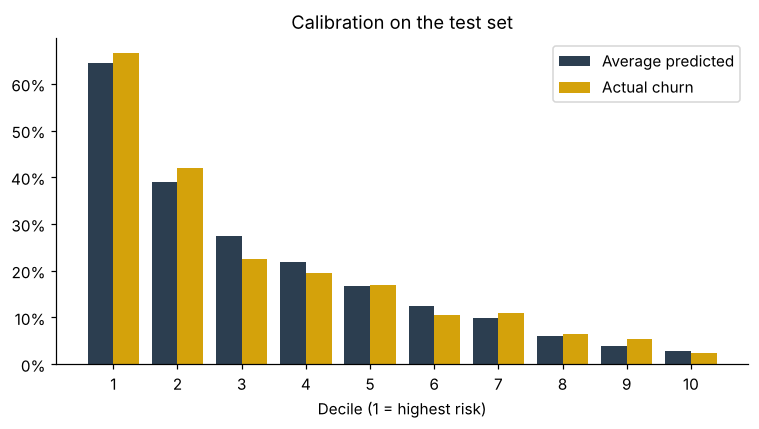

decile,1,2,3,4,5,6,7,8,9,10
avg_predicted,0.644,0.391,0.274,0.220,0.167,0.125,0.099,0.060,0.039,0.027
actual,0.665,0.420,0.225,0.195,0.170,0.105,0.110,0.065,0.055,0.025


In [8]:
p_test = model.predict_proba(X_test)[:, 1]
dev_auc = roc_auc_score(y_test, p_test)
dev_tdp = top_decile_precision(y_test, p_test)
print(f"Test AUC = {dev_auc:.3f}")
print(f"Top-decile precision = {dev_tdp:.1%}  (lift = {dev_tdp:.3f} / {y_test.mean():.3f} = {dev_tdp / y_test.mean():.1f}x the average churn rate)")
print(f"Average predicted churn = {p_test.mean():.1%} vs actual {y_test.mean():.1%}")

d = pd.DataFrame({"y": y_test.values, "p": p_test})
d["decile"] = pd.qcut(d["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
deciles = d.groupby("decile", observed=True).agg(avg_predicted=("p", "mean"), actual=("y", "mean"))
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(1, 11)
ax.bar(x - 0.2, deciles["avg_predicted"], 0.4, color=NAVY, label="Average predicted")
ax.bar(x + 0.2, deciles["actual"], 0.4, color=AMBER, label="Actual churn")
ax.set_xticks(x); ax.set_xlabel("Decile (1 = highest risk)"); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.legend()
ax.set_title("Calibration on the test set")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/02_calibration.png", dpi=120, bbox_inches="tight"); plt.show()
deciles.T

The predicted churn rates track the actual rates closely across the deciles, so the probabilities can be used directly in the retention economics below,
not just for ranking. These test-set values (**AUC and top-decile precision**) become the **development benchmarks** that monitoring compares against.

## 8. What drives the predictions

**Permutation importance:** shuffle one column in the test set and measure how much the AUC drops. A big drop means the model relies on that column.

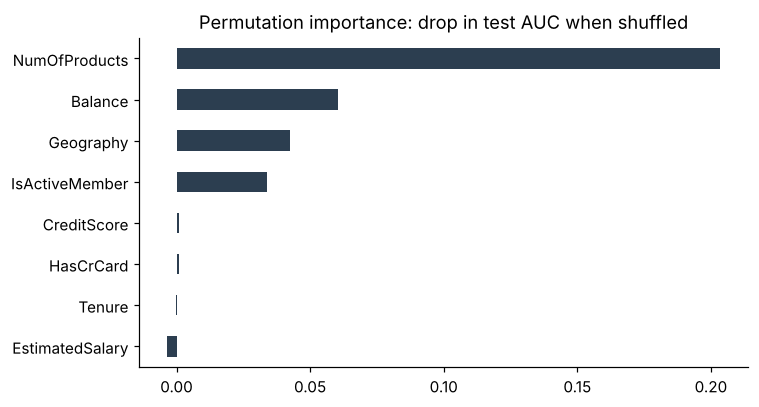

NumOfProducts      0.203
Balance            0.060
Geography          0.043
IsActiveMember     0.034
CreditScore        0.001
HasCrCard          0.001
Tenure            -0.000
EstimatedSalary   -0.004
dtype: float64

In [9]:
perm = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
importance.plot.barh(figsize=(7, 3.8), color=NAVY, title="Permutation importance: drop in test AUC when shuffled")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/03_importance.png", dpi=120, bbox_inches="tight"); plt.show()
importance.sort_values(ascending=False).round(4)

**Number of products** dominates by far, followed by **balance**, **country** and **active membership**. Credit score, tenure, card holding and salary add almost nothing.
The main drivers are things the bank can see and, partly, influence
(for example, a second product or re-engaging an inactive customer). That makes the model's drivers actionable, not just predictive.

## 9. Retention economics: whom to contact

Illustrative assumptions (the Power BI dashboard turns these into adjustable *what-if parameters*):
- **Offer cost: €25** per customer contacted (fee waiver, adviser time)
- **Success rate: 30%**: of the customers who *would* leave, the offer keeps 3 in 10
- **Customer value: €500**: margin kept by retaining a customer

**Expected value of contacting a customer**, step by step:

$$EV = p_{churn} \times \text{success rate} \times \text{value} - \text{cost} = p \times 0.30 \times €500 - €25$$

**Break-even:** EV > 0 when p > 25 ÷ (0.30 × 500) = **16.7%**.

In [10]:
COST, SUCCESS, VALUE = 25, 0.30, 500
breakeven = COST / (SUCCESS * VALUE)
target = p_test > breakeven
ev = (p_test[target] * SUCCESS * VALUE - COST).sum()
realised = (y_test.values[target] * SUCCESS * VALUE).sum() - COST * target.sum()
contact_all = (y_test.values * SUCCESS * VALUE).sum() - COST * len(y_test)

print(f"Break-even probability = {COST} / ({SUCCESS} x {VALUE}) = {breakeven:.1%}")
print(f"Contact customers above break-even: {target.sum():,} of {len(target):,} ({target.mean():.0%}), "
      f"catching {y_test.values[target].sum() / y_test.sum():.0%} of churners")
print(f"  Expected value (from the model's probabilities): €{ev:,.0f}")
print(f"  Realised value (using what actually happened):   €{realised:,.0f}")
print(f"Contact everyone: €{contact_all:,.0f}")

Break-even probability = 25 / (0.3 x 500) = 16.7%
Contact customers above break-even: 892 of 2,000 (45%), catching 78% of churners
  Expected value (from the model's probabilities): €26,089
  Realised value (using what actually happened):   €25,550
Contact everyone: €11,050


Targeting by the model more than doubles the value of contacting everyone. The **expected** value (computed from the model's probabilities) is close to the
**realised** value: calibration is what lets the bank budget a campaign from the model before running it.

## 10. Fairness at development

Gender and age were left out of the model, but their columns are still in the test data, so outcomes can be checked by group.
For each group: average predicted churn vs actual churn (**calibration**), and the share of the group in the top 10% of scores (**flag rate**).

In [11]:
t = test_df.assign(p=p_test)
t["age_band"] = pd.cut(t["Age"], [0, 29, 39, 49, 59, 120], labels=["18–29", "30–39", "40–49", "50–59", "60+"])
t["flagged"] = t["p"] >= np.quantile(p_test, 0.9)
def fairness_table(col):
    g = t.groupby(col, observed=True).agg(customers=("p", "size"), avg_predicted=("p", "mean"),
                                          actual_churn=(TARGET, "mean"), flag_rate=("flagged", "mean"))
    g["predicted_minus_actual"] = g["avg_predicted"] - g["actual_churn"]
    return g
print(fairness_table("Gender").round(3)); print(); print(fairness_table("age_band").round(3))

        customers  avg_predicted  actual_churn  flag_rate  \
Gender                                                      
Female        930          0.209         0.251      0.114   
Male         1070          0.201         0.163      0.088   

        predicted_minus_actual  
Gender                          
Female                  -0.041  
Male                     0.038  

          customers  avg_predicted  actual_churn  flag_rate  \
age_band                                                      
18–29           331          0.171         0.060      0.069   
30–39           860          0.188         0.107      0.074   
40–49           539          0.232         0.317      0.126   
50–59           170          0.281         0.576      0.212   
60+             100          0.180         0.260      0.090   

          predicted_minus_actual  
age_band                          
18–29                      0.110  
30–39                      0.081  
40–49                     -0.085  
50–59

**An uncomfortable but important finding.** Leaving age and gender out does **not** make the model's errors equal across groups:
- It **under-predicts churn for women** (21% predicted vs 25% actual) and **for customers aged 40 and over**, most of all in their 50s (28% predicted vs 58% actual).
  It over-predicts churn for customers under 40.
- So customers in their 50s, who are the most likely to leave, are flagged most often, but far less often than their real risk would justify.

"Fairness through unawareness" (simply removing protected columns) protects against using those attributes directly, but it doesn't guarantee equal accuracy.
Options include adding non-protected features that explain the gap (product mix, life events), applying the same outreach rules to everyone in a high-risk group regardless of score,
or a compliance-approved use of age for benefit-only offers (Section 4). **The model owner's job is to surface this, not to settle it alone.**
This table is also part of monthly monitoring.

## 11. Monitoring design

Once deployed, the model is checked **every month**. Each check has an owner-agreed threshold and an action:

| Check | What it detects | Green | Amber (investigate) | Red (act) |
|---|---|---|---|---|
| **AUC drop** vs development | Ranking quality falling | < 0.03 | 0.03–0.05 | > 0.05 |
| **Score PSI** vs training scores | The customer mix being scored has shifted | < 0.10 | 0.10–0.25 | > 0.25 |
| **Calibration gap** = actual − predicted churn | Probabilities no longer match reality | < 3 pts | 3–5 pts | > 5 pts |
| **Top-decile precision drop** | Targeted customers no longer the ones leaving | < 5 pts | 5–10 pts | > 10 pts |
| **Largest input-feature PSI** | Early warning: an input has shifted before the score does | < 0.10 | 0.10–0.25 | > 0.25 |

**Overall status** = the worst of the five. Fairness by gender, age band and country is reviewed alongside, without automatic thresholds (it needs judgement).

**PSI, step by step** (same as the credit default project): split the *training* distribution into bins; for each bin,
(actual% − expected%) × ln(actual% ÷ expected%); add them up.

**Note on timing:** churn is only known after the outcome window closes, so in real life the performance checks (AUC, calibration) lag the drift checks (PSI) by that window.
The drift checks are the early warning; the performance checks confirm the damage.

In [12]:
THRESHOLDS = {"auc_drop": (0.03, 0.05), "psi": (0.10, 0.25), "calibration_gap": (0.03, 0.05),
              "top_decile_precision_drop": (0.05, 0.10), "max_feature_psi": (0.10, 0.25)}

def psi(expected, actual, categorical=False, n_bins=10):
    expected, actual = pd.Series(expected), pd.Series(actual)
    if categorical:                                    # categories: compare shares per category
        e = expected.value_counts(normalize=True)
        a = actual.value_counts(normalize=True).reindex(e.index, fill_value=0)
    else:                                              # numbers: compare shares per training decile
        edges = np.unique(np.quantile(expected, np.linspace(0, 1, n_bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf
        e = pd.cut(expected, edges).value_counts(normalize=True, sort=False)
        a = pd.cut(actual, edges).value_counts(normalize=True, sort=False).reindex(e.index, fill_value=0)
    e, a = e.clip(lower=1e-4), a.clip(lower=1e-4)    # avoid ln(0)
    return float(((a - e) * np.log(a / e)).sum())

def status(value, amber, red):
    return "Red" if value > red else ("Amber" if value > amber else "Green")

train_scores = model.predict_proba(X_train)[:, 1]

## 12. A simulated production year

Real monitoring data doesn't exist for a public dataset, so a production year is **simulated** from the held-out test customers
(1,000 customers scored each month, January–December 2025):

| Months | Scenario |
|---|---|
| 1–6 | **Stable**: customers drawn at random from the test set |
| 7–12 | **Population drift**: customers from Germany and inactive customers become steadily more common (as if a marketing push or a branch change shifted the mix) |
| 10–12 | **Market event**: a competitor launches a high-rate savings account; a growing share (15%, 25%, 35%) of otherwise loyal customers with balances above €100K leave. The model has never seen this behaviour |

Because each month's outcomes come from real customers (plus the simulated event), the monitoring metrics behave the way real ones would, including ordinary month-to-month noise.

In [13]:
rng = np.random.default_rng(7)
pool = test_df.reset_index(drop=True)
months = []
for m in range(1, 13):
    w = np.ones(len(pool))
    if m >= 7:                                                    # population drift from month 7
        step = m - 6
        w *= np.where(pool["Geography"] == "Germany", 1 + 0.35 * step, 1.0)
        w *= np.where(pool["IsActiveMember"] == 0, 1 + 0.25 * step, 1.0)
    idx = rng.choice(len(pool), 1000, replace=True, p=w / w.sum())
    month = pool.iloc[idx].copy()
    month["month_id"] = m
    month["churned"] = month[TARGET].values
    if m >= 10:                                                   # market event from month 10
        share = {10: 0.15, 11: 0.25, 12: 0.35}[m]
        at_risk = (month["Balance"] > 100_000) & (month["churned"] == 0)
        month.loc[at_risk & (rng.random(len(month)) < share), "churned"] = 1
    months.append(month)
prod = pd.concat(months, ignore_index=True)
prod["p"] = model.predict_proba(prod[FEATURES])[:, 1]
prod["age_band"] = pd.cut(prod["Age"], [0, 29, 39, 49, 59, 120], labels=["18–29", "30–39", "40–49", "50–59", "60+"]).astype(str)
print(f"{len(prod):,} customer-months scored")

12,000 customer-months scored


In [14]:
MONITORED = ["CreditScore", "Tenure", "Balance", "NumOfProducts", "IsActiveMember", "EstimatedSalary", "Geography", "HasCrCard", "Age"]
CATEGORICAL_MONITORED = ("Geography", "NumOfProducts", "IsActiveMember", "HasCrCard")

drift_rows = []
for m, g in prod.groupby("month_id"):
    for f in MONITORED:                            # Age is monitored as a population check, not a model input
        v = psi(train_df[f], g[f], categorical=f in CATEGORICAL_MONITORED)
        drift_rows.append({"month_id": m, "feature": f, "psi": v, "status": status(v, *THRESHOLDS["psi"]),
                           "model_input": f in FEATURES})
feature_drift = pd.DataFrame(drift_rows)
max_input_psi = feature_drift[feature_drift["model_input"]].groupby("month_id")["psi"].max()

rows = []
for m, g in prod.groupby("month_id"):
    auc, tdp = roc_auc_score(g["churned"], g["p"]), top_decile_precision(g["churned"], g["p"])
    r = {"month_id": m, "customers": len(g), "avg_predicted": g["p"].mean(), "actual_churn": g["churned"].mean(),
         "calibration_gap": g["churned"].mean() - g["p"].mean(), "auc": auc, "auc_drop": dev_auc - auc,
         "top_decile_precision": tdp, "top_decile_precision_drop": dev_tdp - tdp,
         "score_psi": psi(train_scores, g["p"]), "max_feature_psi": max_input_psi[m]}
    r["auc_status"] = status(r["auc_drop"], *THRESHOLDS["auc_drop"])
    r["psi_status"] = status(r["score_psi"], *THRESHOLDS["psi"])
    r["calibration_status"] = status(abs(r["calibration_gap"]), *THRESHOLDS["calibration_gap"])
    r["top_decile_status"] = status(r["top_decile_precision_drop"], *THRESHOLDS["top_decile_precision_drop"])
    r["feature_drift_status"] = status(r["max_feature_psi"], *THRESHOLDS["max_feature_psi"])
    levels = [r[k] for k in ("auc_status", "psi_status", "calibration_status", "top_decile_status", "feature_drift_status")]
    r["overall_status"] = "Red" if "Red" in levels else ("Amber" if "Amber" in levels else "Green")
    rows.append(r)
monitoring = pd.DataFrame(rows)
monitoring[["month_id", "avg_predicted", "actual_churn", "calibration_gap", "auc", "score_psi", "max_feature_psi",
            "auc_status", "psi_status", "calibration_status", "feature_drift_status", "overall_status"]]

,month_id,avg_predicted,actual_churn,calibration_gap,auc,score_psi,max_feature_psi,auc_status,psi_status,calibration_status,feature_drift_status,overall_status
0,1,0.202,0.201,-0.001,0.808,0.013,0.021,Green,Green,Green,Green,Green
1,2,0.203,0.191,-0.012,0.802,0.011,0.021,Green,Green,Green,Green,Green
2,3,0.203,0.193,-0.010,0.780,0.015,0.019,Green,Green,Green,Green,Green
3,4,0.210,0.222,0.012,0.776,0.008,0.028,Green,Green,Green,Green,Green
4,5,0.218,0.199,-0.019,0.794,0.017,0.022,Green,Green,Green,Green,Green
5,6,0.206,0.197,-0.009,0.806,0.011,0.017,Green,Green,Green,Green,Green
6,7,0.225,0.224,-0.001,0.820,0.038,0.025,Green,Green,Green,Green,Green
7,8,0.228,0.236,0.008,0.790,0.048,0.066,Green,Green,Green,Green,Green
8,9,0.239,0.252,0.013,0.804,0.075,0.132,Green,Green,Green,Amber,Amber
9,10,0.241,0.296,0.055,0.745,0.088,0.188,Red,Green,Red,Amber,Red


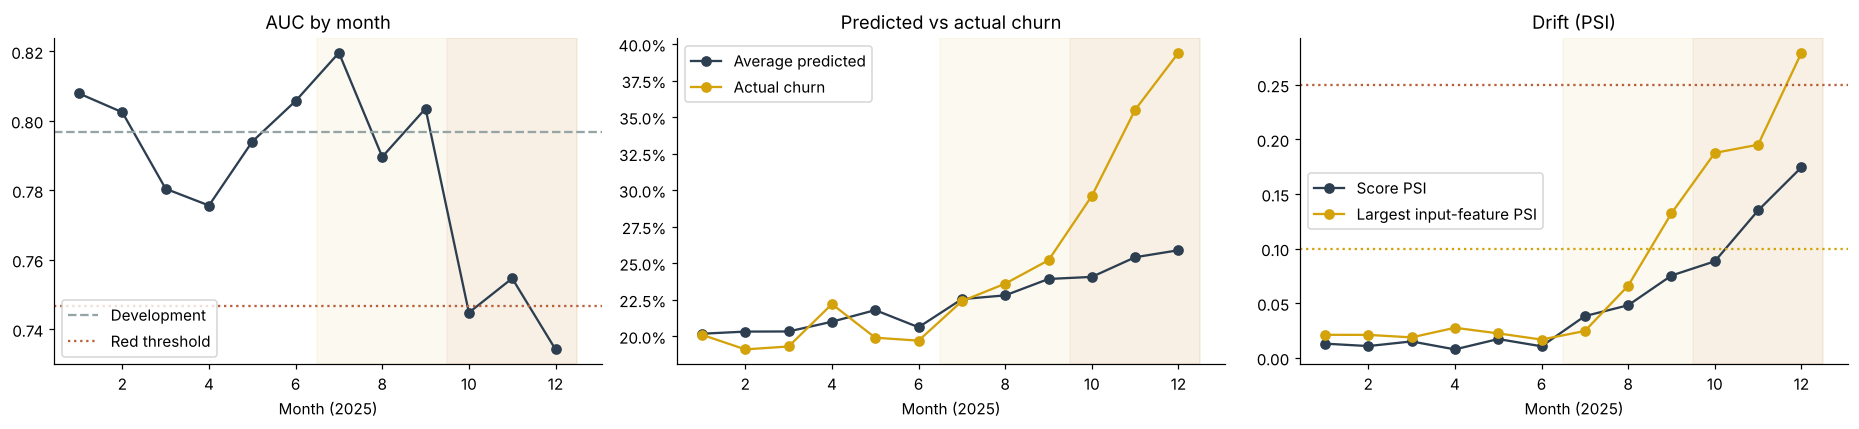

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
m = monitoring["month_id"]
axes[0].plot(m, monitoring["auc"], "o-", color=NAVY); axes[0].axhline(dev_auc, color=GREY, ls="--", label="Development")
axes[0].axhline(dev_auc - 0.05, color=RED, ls=":", label="Red threshold"); axes[0].set_title("AUC by month"); axes[0].legend()
axes[1].plot(m, monitoring["avg_predicted"], "o-", color=NAVY, label="Average predicted")
axes[1].plot(m, monitoring["actual_churn"], "o-", color=AMBER, label="Actual churn")
axes[1].yaxis.set_major_formatter(PercentFormatter(1)); axes[1].set_title("Predicted vs actual churn"); axes[1].legend()
axes[2].plot(m, monitoring["score_psi"], "o-", color=NAVY, label="Score PSI")
axes[2].plot(m, monitoring["max_feature_psi"], "o-", color=AMBER, label="Largest input-feature PSI")
axes[2].axhline(0.10, color=AMBER, ls=":"); axes[2].axhline(0.25, color=RED, ls=":"); axes[2].set_title("Drift (PSI)"); axes[2].legend()
for ax in axes:
    ax.axvspan(6.5, 12.5, color=AMBER, alpha=0.06); ax.axvspan(9.5, 12.5, color=RED, alpha=0.06); ax.set_xlabel("Month (2025)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/04_monitoring_year.png", dpi=120, bbox_inches="tight"); plt.show()

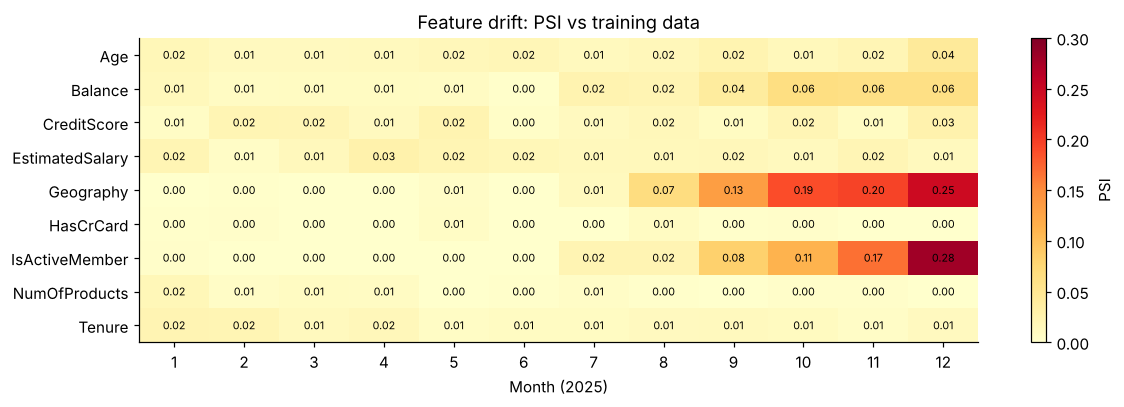

In [16]:
heat = feature_drift.pivot(index="feature", columns="month_id", values="psi")
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat.values, cmap="YlOrRd", vmin=0, vmax=0.3, aspect="auto")
ax.set_xticks(range(12), heat.columns); ax.set_yticks(range(len(heat)), heat.index)
for r in range(heat.shape[0]):
    for c in range(heat.shape[1]):
        ax.text(c, r, f"{heat.values[r, c]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="PSI"); ax.set_xlabel("Month (2025)"); ax.set_title("Feature drift: PSI vs training data")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/05_feature_drift.png", dpi=120, bbox_inches="tight"); plt.show()

## 13. Reading the year: what monitoring caught, and what to do

| Months | Status | What happened | Response |
|---|---|---|---|
| 1–8 | Green | Ordinary noise: monthly AUC moves by about ±0.02 around development with 1,000 customers | None; report as usual |
| 9 | **Amber** | **Geography drift** (PSI ≈ 0.13): more customers from Germany. The score PSI and performance are still green | **Investigate**: confirm the cause with the business (a campaign? a branch change?); check the model's accuracy for German customers |
| 10 | **Red** | The **market event** hits: actual churn jumps above predicted (calibration gap > 5 pts) and AUC falls more than 0.05 below development | **Act**: alert model risk and the business; temporarily recalibrate (or add a manual overlay for high-balance customers); start retraining |
| 11–12 | Red | Gap widens; score PSI reaches amber, and inactive-member drift goes red by month 12 | Retrain on recent data including the event, revalidate (including out-of-time), and redeploy through model governance |

**Lessons**
1. **Feature drift gave the earliest warning** (month 9), before the score itself drifted (month 11). Watching inputs, not just outputs, buys time.
2. **Drift and performance tell different stories.** The market event changed *behaviour*, not the customer mix, so PSI barely moved in month 10 while calibration and AUC failed.
   Monitoring needs both kinds of check.
3. **Top-decile precision stayed green throughout**, and even rose, because more customers were leaving overall. A dashboard showing only that metric would have missed the problem.

## 14. Exporting tables for Power BI

| Table | Grain | Purpose |
|---|---|---|
| `months.csv` | One row per month | Date dimension: month start, label, scenario phase |
| `monitoring_monthly.csv` | One row per month | All monitoring metrics and RAG statuses |
| `monitoring_status.csv` | Month × check | The same five checks in "long" form, for the status grid |
| `feature_drift.csv` | Month × feature | PSI per monitored feature (heatmap) |
| `fairness_monthly.csv` | Month × group | Predicted vs actual churn and flag rate by gender, age band and country |
| `scored_customers.csv` | Customer × month | Every scored customer: inputs, probability, risk band, flag, outcome (for drill-down and the retention what-if) |
| `thresholds.csv` | One row per check | Amber and red thresholds, and why each check exists |
| `model_comparison.csv` | One row per model | CV and test results; which model was selected |

All month-level tables relate to `months[month_id]`; `monitoring_status[check]` also relates to `thresholds[metric]`.

In [17]:
months_dim = pd.DataFrame({"month_id": range(1, 13)})
months_dim["month_start"] = [(pd.Timestamp("2025-01-01") + pd.DateOffset(months=i - 1)).date() for i in months_dim["month_id"]]
months_dim["month_label"] = [pd.Timestamp(d).strftime("%b %Y") for d in months_dim["month_start"]]
months_dim["phase"] = ["Stable"] * 6 + ["Population drift"] * 3 + ["Drift + market event"] * 3

p = prod.copy()
p["flagged"] = p.groupby("month_id")["p"].transform(lambda s: s >= s.quantile(0.9)).astype(int)   # top 10% each month
fair_rows = []
for dim, col in [("Gender", "Gender"), ("Age band", "age_band"), ("Geography", "Geography")]:
    for (mo, grp), g in p.groupby(["month_id", col]):
        fair_rows.append({"month_id": mo, "dimension": dim, "group": grp, "customers": len(g), "avg_predicted": g["p"].mean(),
                          "actual_churn": g["churned"].mean(), "flagged_share": g["flagged"].mean()})
fairness_monthly = pd.DataFrame(fair_rows)

p["risk_band"] = pd.cut(p["p"], [-0.01, 0.10, 0.25, 0.50, 1.01], labels=["Low", "Medium", "High", "Very high"]).astype(str)
scored = pd.DataFrame({
    "month_id": p["month_id"], "customer_id": p["CustomerId"], "geography": p["Geography"], "gender": p["Gender"],
    "age": p["Age"], "age_band": p["age_band"], "credit_score": p["CreditScore"], "tenure_years": p["Tenure"],
    "balance": p["Balance"].round(2), "products": p["NumOfProducts"], "has_credit_card": p["HasCrCard"],
    "is_active_member": p["IsActiveMember"], "estimated_salary": p["EstimatedSalary"].round(2),
    "churn_probability": p["p"].round(4), "risk_band": p["risk_band"],
    "risk_band_order": p["risk_band"].map({"Low": 1, "Medium": 2, "High": 3, "Very high": 4}),   # lets Power BI sort Low -> Very high
    "flagged_top_decile": p["flagged"], "churned": p["churned"]})

# Status grid for Power BI: one row per month x check (a matrix needs this "long" shape)
checks = [("AUC drop vs development", "auc_drop", "auc_status"), ("Score PSI", "score_psi", "psi_status"),
          ("Calibration gap (absolute)", "calibration_gap", "calibration_status"),
          ("Top-decile precision drop", "top_decile_precision_drop", "top_decile_status"),
          ("Largest input-feature PSI", "max_feature_psi", "feature_drift_status")]
monitoring_status = pd.DataFrame([
    {"month_id": int(r["month_id"]), "check": check, "check_order": order, "value": r[value_col], "status": r[status_col],
     "status_rank": {"Green": 1, "Amber": 2, "Red": 3}[r[status_col]]}
    for _, r in monitoring.iterrows() for order, (check, value_col, status_col) in enumerate(checks, start=1)])

thresholds = pd.DataFrame([
    {"metric": "AUC drop vs development", "amber_above": 0.03, "red_above": 0.05, "why": "Ranking quality: can the model still tell churners from stayers?"},
    {"metric": "Score PSI", "amber_above": 0.10, "red_above": 0.25, "why": "Population drift: are we scoring a different customer mix than the model was built on?"},
    {"metric": "Calibration gap (absolute)", "amber_above": 0.03, "red_above": 0.05, "why": "Are predicted churn rates still close to actual churn?"},
    {"metric": "Top-decile precision drop", "amber_above": 0.05, "red_above": 0.10, "why": "Campaign efficiency: are the customers we target still the ones who leave?"},
    {"metric": "Largest input-feature PSI", "amber_above": 0.10, "red_above": 0.25, "why": "Early warning: has any model input shifted, even before the score does?"}])

tables = {"months": months_dim, "monitoring_monthly": monitoring.round(4), "monitoring_status": monitoring_status.round(4),
          "feature_drift": feature_drift.round(4),
          "fairness_monthly": fairness_monthly.round(4), "scored_customers": scored, "thresholds": thresholds,
          "model_comparison": comparison.round(4)}
for name, table in tables.items():
    table.to_csv(os.path.join(EXPORT_DIR, f"{name}.csv"), index=False)
    print(f"{name + '.csv':24s} {len(table):>6,} rows x {table.shape[1]} columns")

months.csv                   12 rows x 4 columns
monitoring_monthly.csv       12 rows x 17 columns
monitoring_status.csv        60 rows x 6 columns
feature_drift.csv           108 rows x 5 columns
fairness_monthly.csv        120 rows x 7 columns
scored_customers.csv     12,000 rows x 18 columns
thresholds.csv                5 rows x 4 columns
model_comparison.csv          4 rows x 5 columns


## 15. Limitations

- **One bank, three countries, one snapshot**, with no dates: the churn window and the timing of the data aren't documented.
- **The production year is simulated.** The drift scenarios are plausible but invented; their purpose is to show how the monitoring responds.
- **Fairness gap:** excluding age and gender leaves the model less accurate for women and for customers in their 40s and 50s (Section 10). This needs a decision, documented in the model card.
- **The economics are illustrative**: offer cost, success rate and customer value would come from finance and from past campaign results.
- **Uplift, not just risk:** the model predicts *who will leave*, not *who will stay because of the offer*. A next step would be an uplift model trained on a past randomised campaign (see the planned A/B testing project).

The full model documentation is in `MODEL_CARD.md`. The same logic is in `src/churn_model.py`; running `python -m src.churn_model` regenerates the Power BI tables,
and the automated tests in `tests/` confirm it matches this notebook.